Publication adaptation: workspace labels and runtime paths have been renamed. Saved scientific results and embedded image bytes are retained from the recorded run; this source notebook has not been recomputed after that adaptation. Printed historical checksums describe that recorded run. Current released-file checksums are in the publication source map.

# Singh cellular landscape and WT metaclone histories

This notebook displays the preserved cell and clone embeddings without refitting either geometry or the metaclone partition. It adds descriptive, source-linked views of the corrected lineage-family cohort. These maps do not test mutation effects, measure growth, or establish cell trajectories through time. HSC and MPP annotations are displayed jointly as HSPCs; no separate HSC/MPP comparisons are made.

Environment **chronoclone**, existing Conda-compatible installation at `/path/to/ChronoClone/.runtime/chronoclone`; Jupyter kernel **chronoclone**. No package installation or environment mutation. Exact language/package versions and the full MacBook-local execution command are printed in the first code cell. Dense full-landscape marks are rasterized inside the editable SVG; labels and overlays remain editable.


In [1]:

from pathlib import Path
import sys, json, hashlib, platform, importlib.metadata as metadata
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import Normalize
from IPython.display import display
P=Path('/path/to/ChronoClone')
O=P/'analysis_workspace/singh/singh_landscape_expansion_20260911'
RUN=P/'analysis_workspace/singh/singh_reference_response_20260911'
for name in ['panels','tables','reports']:(O/name).mkdir(parents=True,exist_ok=True)
runner=P/'analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py'
env={'environment':'chronoclone','manager':'existing Conda-compatible installation','path':str(Path(sys.executable).parent.parent),'kernel':'chronoclone','Python':platform.python_version(),'versions':{p:metadata.version(p) for p in ['numpy','pandas','scipy','anndata','matplotlib','nbformat']},'execution_command':f'{sys.executable} {runner} {O/"0001_singh_landscape_and_reference.ipynb"}'}
assert env['path']=='/path/to/ChronoClone/.runtime/chronoclone'
display(env);(O/'reports/environment.json').write_text(json.dumps(env,indent=2))
plt.rcParams.update({'svg.fonttype':'none','font.family':'Arial','font.size':16,'axes.labelsize':17,'xtick.labelsize':14,'ytick.labelsize':14,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
CTS=['HSPC','GMP','Basophil','Neutrophil','Monocyte','Ery','Mk']
COLORS={'HSPC':'#777777','GMP':'#BA9BC9','Mk':'#4575B4','Ery':'#D73027','Basophil':'#50A653','Monocyte':'#AF3362','Neutrophil':'#E89A32'}
LABELS={'HSPC':'HSPC','GMP':'GMP','Basophil':'Basophil','Neutrophil':'Neutrophil','Monocyte':'Monocyte','Ery':'Erythroid','Mk':'Megakaryocyte'}
MCS=[0,1,2,3,4,5,6,7,9,10,11,12,13,15,16,17,19]
MC_COLORS={0:'#f77189',1:'#f8763b',2:'#d28e32',3:'#b79932',4:'#9ea231',5:'#7caa31',6:'#31b345',7:'#34b081',9:'#35ae9a',10:'#36acad',11:'#38aac1',12:'#3aa6dd',13:'#7699f4',15:'#b087f4',16:'#df6df4',17:'#f563d8',19:'#f66ab2'}


{'environment': 'chronoclone',
 'manager': 'existing Conda-compatible installation',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'Python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scipy': '1.17.1',
  'anndata': '0.12.18',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4'},
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/0001_singh_landscape_and_reference.ipynb'}

In [2]:

full_path=P/'data/processed/singh_strack/adata_valid_keep_all.h5ad'
pal_path=P/'data/processed/singh_strack/adata_valid_palantir_20260626.h5ad'
full=ad.read_h5ad(full_path,backed='r')
F=full.obs[['cell_type']].copy();F['ct']=F.cell_type.astype(str).replace({'HSC':'HSPC','MPP':'HSPC'})
F[['x','y']]=np.asarray(full.obsm['X_umap'])[:,:2]
assert F.index.is_unique and len(F)==96662 and set(F.ct)==set(CTS)
full.file.close()
D=pd.read_csv(RUN/'dynamics/tables/cells_resolved.csv',index_col='cell_id')
assert len(D)==14896 and D.index.is_unique and D.clone.nunique()==1516 and sorted(D.mc.unique())==MCS
assert D.index.isin(F.index).all()
assert (D.ct.to_numpy()==F.loc[D.index,'ct'].to_numpy()).all()
D=D.join(F[['x','y']],validate='one_to_one')
pal=ad.read_h5ad(pal_path,backed='r')
K=pd.DataFrame(np.asarray(pal.obsm['X_umap'])[:,:2],index=pal.obs_names,columns=['x','y'])
assert np.array_equal(K.loc[D.index].to_numpy(),D[['x','y']].to_numpy())
pal.file.close()
embedding_path=P/'analysis_workspace/final_release/source_tables/figure3/fig3c_full_trajectory_embedding.csv'
E=pd.read_csv(embedding_path,usecols=['clone_id','metaclone','UMAP1','UMAP2','feature_scope'])
registry=pd.read_csv(RUN/'dynamics/tables/lineage_family_registry.csv')
assert E.clone_id.is_unique and set(E.clone_id)==set(registry.clone)
assert E.set_index('clone_id').metaclone.sort_index().equals(registry.set_index('clone').mc.sort_index())
CA=pd.read_csv(RUN/'dynamics/tables/clone_arm_table.csv')
assert not CA.duplicated(['mc','day','arm','stratum','clone']).any()
assert np.allclose(CA[CTS].sum(axis=1),1)
D.to_csv(O/'tables/resolved_cells_with_original_coordinates.csv',index_label='cell_id')
F.to_csv(O/'tables/full_cell_landscape_coordinates.csv',index_label='cell_id')
E.to_csv(O/'tables/frozen_clone_trajectory_coordinates.csv',index=False)
low=F[['x','y']].min()-.4;high=F[['x','y']].max()+.4
BOUNDS=tuple(float(x) for x in (low.x,high.x,low.y,high.y))
audit={'full_cells':len(F),'resolved_cells':len(D),'resolved_families':D.clone.nunique(),'metaclones':len(MCS),'cell_geometry_exact':True,'clone_registry_exact':True,'no_embedding_refit':True,'full_bounds':list(BOUNDS),'annotation_palette':'current manuscript CT_COLORS; pooled HSPC','unresolved_cells_not_overlaid':True}
(O/'reports/geometry_cohort_checks.json').write_text(json.dumps(audit,indent=2));display(audit)
sources=[full_path,pal_path,embedding_path,RUN/'dynamics/tables/cells_resolved.csv',RUN/'dynamics/tables/clone_arm_table.csv']
manifest=[]
for p in sources:
    h=hashlib.sha256()
    with p.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    manifest.append({'source':str(p.relative_to(P)),'sha256':h.hexdigest()})
pd.DataFrame(manifest).to_csv(O/'reports/source_manifest.csv',index=False)
display(F.ct.value_counts().reindex(CTS).rename('cells'))


{'full_cells': 96662,
 'resolved_cells': 14896,
 'resolved_families': 1516,
 'metaclones': 17,
 'cell_geometry_exact': True,
 'clone_registry_exact': True,
 'no_embedding_refit': True,
 'full_bounds': [-5.968404293060303,
  7.454280853271484,
  -9.03365707397461,
  5.982400894165039],
 'annotation_palette': 'current manuscript CT_COLORS; pooled HSPC',
 'unresolved_cells_not_overlaid': True}

ct
HSPC          53293
GMP           14823
Basophil       4550
Neutrophil     2734
Monocyte       2394
Ery            1536
Mk            17332
Name: cells, dtype: int64

Original single-cell geometry, colored by the pooled source annotation. Color identity follows the existing manuscript palette.

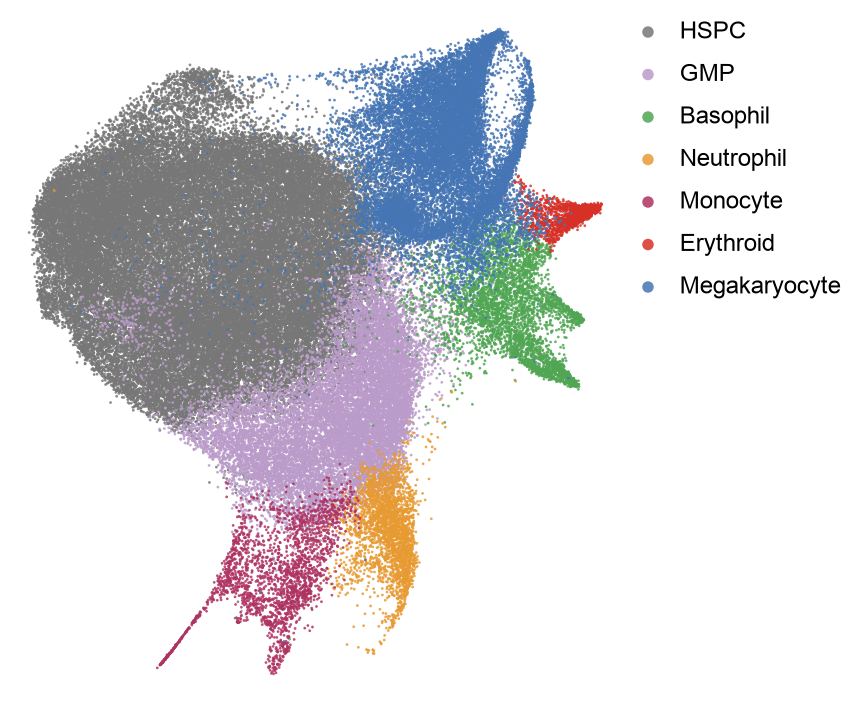

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/panels/singh_cell_type_landscape.svg


In [3]:

plot=F.sample(frac=1,random_state=20260911)
fig,ax=plt.subplots(figsize=(8.2,6.5))
for ct in CTS:
    z=plot.loc[plot.ct==ct]
    ax.scatter(z.x,z.y,s=3.2,c=COLORS[ct],edgecolors='none',alpha=.85,rasterized=True,label=LABELS[ct])
ax.set(xlim=BOUNDS[:2],ylim=BOUNDS[2:],aspect='equal',xticks=[],yticks=[])
ax.set_axis_off()
legend=ax.legend(loc='upper left',bbox_to_anchor=(.99,1.0),frameon=False,markerscale=4.2,handletextpad=.3,borderaxespad=0,labelspacing=.8,fontsize=16)
fig.subplots_adjust(left=.015,right=.69,bottom=.025,top=.98)
stem=O/'panels/singh_cell_type_landscape'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',pad_inches=.10)
fig.savefig(stem.with_suffix('.png'),dpi=320,bbox_inches='tight',pad_inches=.10)
display(fig);plt.close(fig);print(stem.with_suffix('.svg'))


The resolved lineage-linked cells colored by the stored Palantir developmental coordinate, over the original full-cell context.

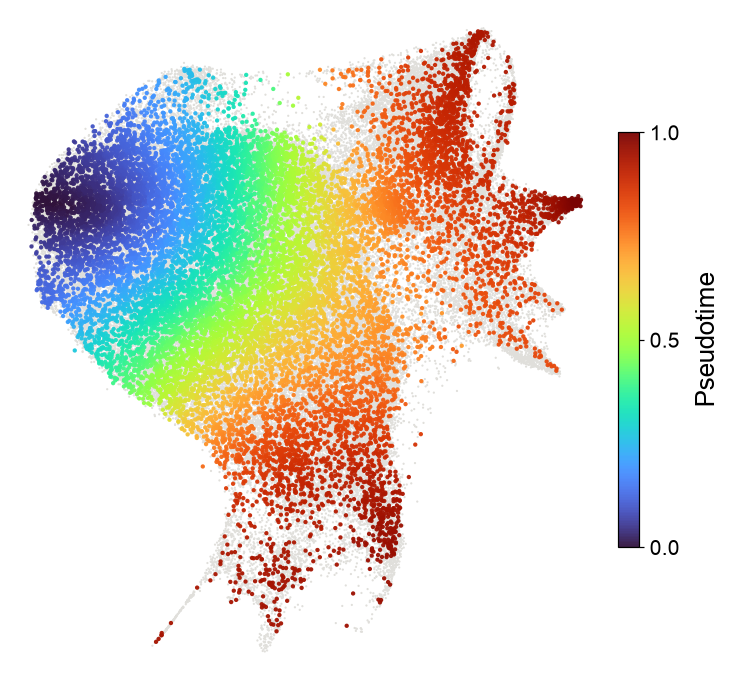

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/panels/singh_resolved_pseudotime_landscape.svg


In [4]:

plot=D.sort_values('psi')
assert plot.psi.between(0,1).all()
fig,ax=plt.subplots(figsize=(7.6,6.3))
ax.scatter(F.x,F.y,s=2.1,c='#e0dfdb',edgecolors='none',rasterized=True)
marks=ax.scatter(plot.x,plot.y,s=8,c=plot.psi,cmap='turbo',vmin=0,vmax=1,edgecolors='none',alpha=.95)
ax.set(xlim=BOUNDS[:2],ylim=BOUNDS[2:],aspect='equal',xticks=[],yticks=[]);ax.set_axis_off()
cb=fig.colorbar(marks,ax=ax,fraction=.034,pad=.025,shrink=.63,ticks=[0,.5,1]);cb.set_label('Pseudotime',labelpad=10)
fig.subplots_adjust(left=.02,right=.92,bottom=.03,top=.98)
stem=O/'panels/singh_resolved_pseudotime_landscape'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',pad_inches=.10)
fig.savefig(stem.with_suffix('.png'),dpi=320,bbox_inches='tight',pad_inches=.10)
display(fig);plt.close(fig);print(stem.with_suffix('.svg'))


A separate, frozen clone embedding displays the WT temporal representation. Each point is a lineage family, not a cell. Distances are not developmental pseudotime.

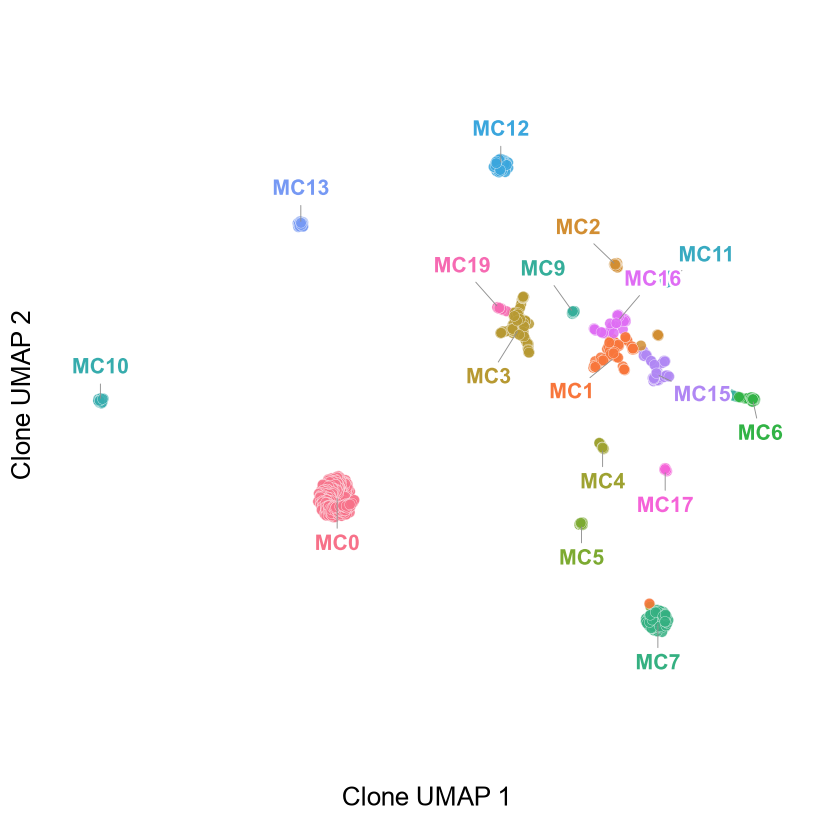

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/panels/singh_wt_clone_trajectory_embedding.svg


In [5]:

plot=E.copy()
centers=plot.groupby('metaclone')[['UMAP1','UMAP2']].median().reindex(MCS)
fig,ax=plt.subplots(figsize=(7.5,7.5))
ax.scatter(plot.UMAP1,plot.UMAP2,s=48,c=plot.metaclone.map(MC_COLORS),edgecolors='#ffffff',linewidths=.25,alpha=.85)
offsets={0:(0,-32),1:(-28,-23),2:(-25,24),3:(-20,-32),4:(0,-23),5:(0,-23),6:(5,-23),7:(0,-28),9:(-20,28),10:(0,22),11:(25,15),12:(0,23),13:(0,23),15:(30,-14),16:(23,27),17:(0,-24),19:(-24,27)}
for mc,row in centers.iterrows():
    ax.annotate(f'MC{mc}',(row.UMAP1,row.UMAP2),xytext=offsets[mc],textcoords='offset points',fontsize=14,fontweight='bold',ha='center',va='center',color=MC_COLORS[mc],arrowprops={'arrowstyle':'-','color':'#909090','lw':.6},path_effects=[pe.withStroke(linewidth=3,foreground='white')])
ax.set_aspect('equal',adjustable='datalim');ax.margins(.09)
ax.set(xticks=[],yticks=[],xlabel='Clone UMAP 1',ylabel='Clone UMAP 2')
for spine in ax.spines.values():spine.set_visible(False)
fig.tight_layout(pad=.5)
stem=O/'panels/singh_wt_clone_trajectory_embedding'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',pad_inches=.10)
fig.savefig(stem.with_suffix('.png'),dpi=320,bbox_inches='tight',pad_inches=.10)
display(fig);plt.close(fig);print(stem.with_suffix('.svg'))


WT cell-state composition across the complete reference registry. Each recovered family is averaged within sequencing sample, followed by equal averaging of observed sample means. Missing snapshots remain missing, not zero compositions.

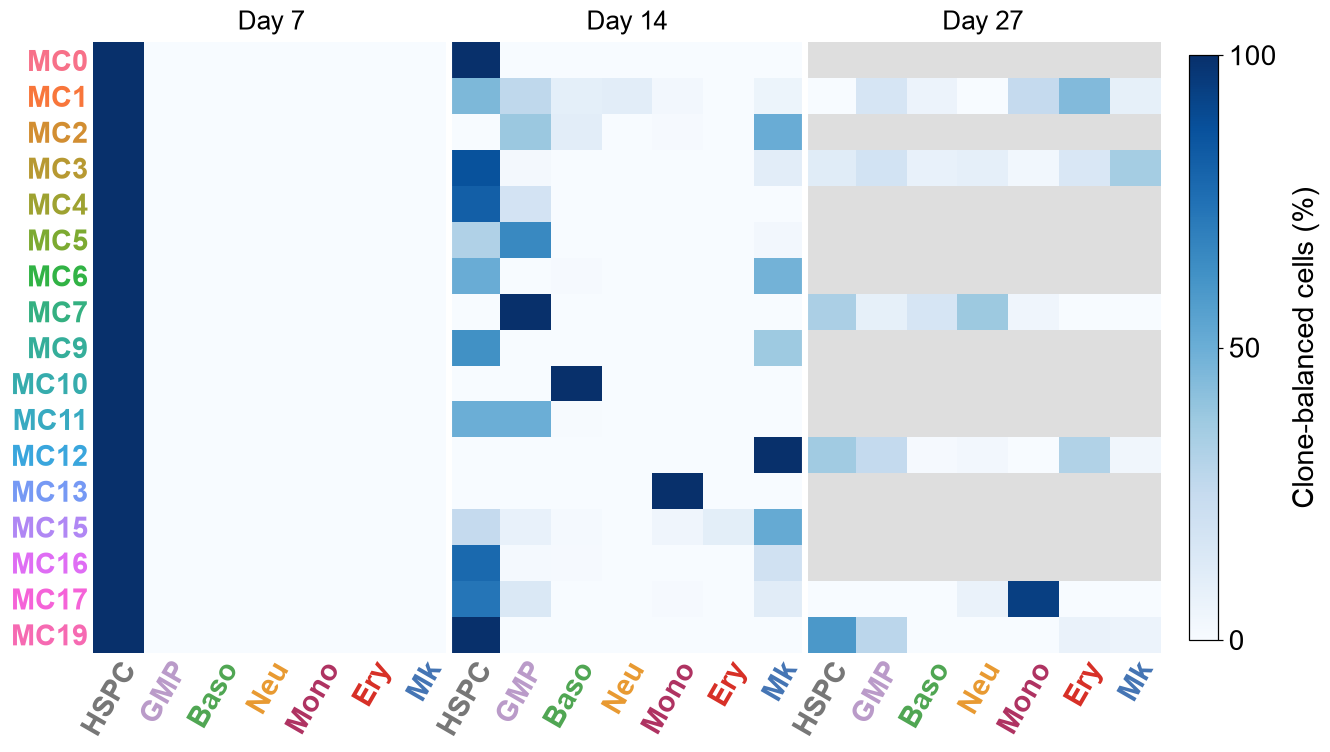

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/panels/singh_wt_all_metaclone_composition.svg


In [6]:

wt=CA.loc[CA.arm=='WT']
per_sample=wt.groupby(['mc','day','stratum'])[CTS].mean()
means=per_sample.groupby(['mc','day']).mean()
columns=pd.MultiIndex.from_product([['D7','D14','D27'],CTS],names=['day','cell_type'])
matrix=means.stack().unstack([1,2]).reindex(index=MCS,columns=columns)
assert np.allclose(matrix.T.groupby(level='day').sum(min_count=1).T.stack().to_numpy(),1)
matrix.to_csv(O/'tables/wt_metaclone_composition_matrix.csv')
fig,ax=plt.subplots(figsize=(12.1,7.6))
cmap=plt.colormaps['Blues'].copy();cmap.set_bad('#dedede')
im=ax.imshow(matrix.to_numpy(),aspect='auto',vmin=0,vmax=1,cmap=cmap,interpolation='nearest')
short={'HSPC':'HSPC','GMP':'GMP','Basophil':'Baso','Neutrophil':'Neu','Monocyte':'Mono','Ery':'Ery','Mk':'Mk'}
ax.set_xticks(range(len(columns)),[short[ct] for _,ct in columns],rotation=60,ha='right',rotation_mode='anchor',fontsize=19)
for tick,(_,ct) in zip(ax.get_xticklabels(),columns):tick.set_color(COLORS[ct]);tick.set_fontweight('bold')
ax.set_yticks(range(len(MCS)),[f'MC{x}' for x in MCS],fontsize=19)
for tick,mc in zip(ax.get_yticklabels(),MCS):tick.set_color(MC_COLORS[mc]);tick.set_fontweight('bold')
for x in [6.5,13.5]:ax.axvline(x,color='white',lw=4)
for x,label in [(3,'Day 7'),(10,'Day 14'),(17,'Day 27')]:ax.text(x,-1.05,label,ha='center',va='center',fontsize=17)
ax.tick_params(length=0);ax.spines[['left','bottom']].set_visible(False)
cb=fig.colorbar(im,ax=ax,fraction=.026,pad=.025,ticks=[0,.5,1]);cb.set_ticklabels(['0','50','100']);cb.ax.tick_params(labelsize=18);cb.set_label('Clone-balanced cells (%)',labelpad=10,fontsize=19)
fig.subplots_adjust(left=.085,right=.93,bottom=.18,top=.91)
stem=O/'panels/singh_wt_all_metaclone_composition'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',pad_inches=.10)
fig.savefig(stem.with_suffix('.png'),dpi=320,bbox_inches='tight',pad_inches=.10)
display(fig);plt.close(fig);print(stem.with_suffix('.svg'))


Observed lineage-family recovery across the seven genuinely sampled arm-time combinations. These are sample support counts, not clone sizes or growth rates.

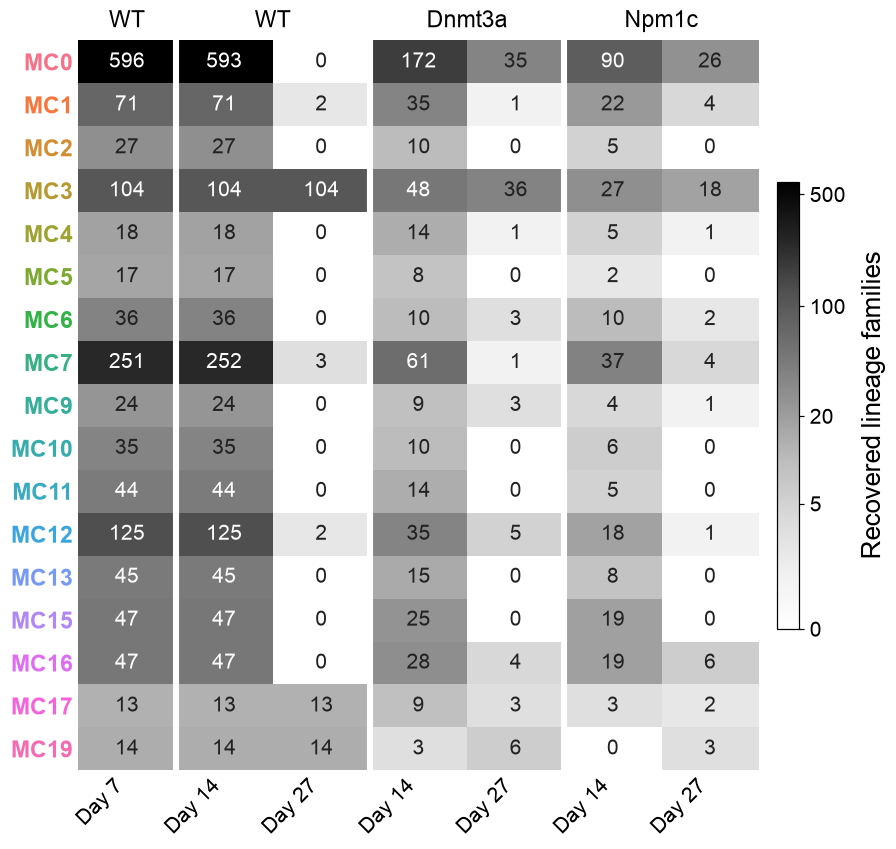

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/panels/singh_all_metaclone_recovery.svg


In [7]:

combinations=[('WT','D7'),('WT','D14'),('WT','D27'),('Dnmt3a','D14'),('Dnmt3a','D27'),('Npm1c','D14'),('Npm1c','D27')]
support=D.groupby(['mc','arm','day']).agg(cells=('clone','size'),families=('clone','nunique'))
columns=pd.MultiIndex.from_tuples(combinations,names=['arm','day'])
matrix=support.families.unstack(['arm','day']).reindex(index=MCS,columns=columns).fillna(0).astype(int)
matrix.to_csv(O/'tables/all_metaclone_recovery_matrix.csv')
fig,ax=plt.subplots(figsize=(8.4,8.4))
im=ax.imshow(np.log1p(matrix.to_numpy()),aspect='auto',cmap='Greys',vmin=0,vmax=np.log1p(matrix.to_numpy().max()),interpolation='nearest')
for y in range(len(MCS)):
    for x in range(len(columns)):
        n=int(matrix.iloc[y,x]);ax.text(x,y,str(n),ha='center',va='center',fontsize=14,color='white' if np.log1p(n)>.57*np.log1p(matrix.to_numpy().max()) else '#222222')
ax.set_yticks(range(len(MCS)),[f'MC{x}' for x in MCS],fontsize=15)
for tick,mc in zip(ax.get_yticklabels(),MCS):tick.set_color(MC_COLORS[mc]);tick.set_fontweight('bold')
ax.set_xticks(range(len(columns)),['Day '+d[1:] for _,d in columns],rotation=45,ha='right',fontsize=14)
for x,label in [(0,'WT'),(1.5,'WT'),(3.5,'Dnmt3a'),(5.5,'Npm1c')]:ax.text(x,-.95,label,ha='center',va='center',fontsize=15)
for x in [.5,2.5,4.5]:ax.axvline(x,color='white',lw=4)
ax.tick_params(length=0);ax.spines[['left','bottom']].set_visible(False)
cb=fig.colorbar(im,ax=ax,fraction=.031,pad=.025,ticks=np.log1p([0,5,20,100,500]));cb.set_ticklabels(['0','5','20','100','500']);cb.set_label('Recovered lineage families',labelpad=10)
fig.subplots_adjust(left=.11,right=.89,bottom=.14,top=.93)
stem=O/'panels/singh_all_metaclone_recovery'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',pad_inches=.10)
fig.savefig(stem.with_suffix('.png'),dpi=320,bbox_inches='tight',pad_inches=.10)
display(fig);plt.close(fig);print(stem.with_suffix('.svg'))


In [8]:

panel_manifest=[]
for path in sorted((O/'panels').glob('*')):
    if path.suffix in ['.svg','.png']:
        panel_manifest.append({'file':str(path.relative_to(O)),'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),'bytes':path.stat().st_size})
pd.DataFrame(panel_manifest).to_csv(O/'reports/panel_manifest.csv',index=False)
display(pd.DataFrame(panel_manifest));print('No partition, embedding, expression model, or inferential test was refitted.')


,file,sha256,bytes
0,panels/singh_all_metaclone_recovery.png,e653b7ceaf81ebf25effaf6205ecceb22dc6e836704fc5...,348297
1,panels/singh_all_metaclone_recovery.svg,277e612662bf10441320e2b16ba6d07f16d7317844d55f...,43076
2,panels/singh_cell_type_landscape.png,2ab405effe41ee9f488c7cec5fc5d48023a47a1e2bec20...,2039677
3,panels/singh_cell_type_landscape.svg,9db2e6b7541733b355e2bf13d4827dba84aa446ac4e835...,469045
4,panels/singh_resolved_pseudotime_landscape.png,c49869455d1b521b72fe53cf87cfed04a1fb20be91ac7b...,1997374
5,panels/singh_resolved_pseudotime_landscape.svg,b0172dc801f9f3e2faa6e0361c65fd29cb6ffb683c2fdb...,2709535
6,panels/singh_wt_all_metaclone_composition.png,445c43f23640e7fc444980f2fa1d9217195e269bf09e6b...,278747
7,panels/singh_wt_all_metaclone_composition.svg,c753d1039a22cb25c8b6ca5b24b79c8d9409cd4d5c80ec...,23609
8,panels/singh_wt_clone_trajectory_embedding.png,1e0cb427db933c34c0959d9b689c7a83e5f4bd11ec19ff...,278323
9,panels/singh_wt_clone_trajectory_embedding.svg,9c98f6e2be15c4e0035c05de6f7753942ec8c690c8a8e2...,414058


No partition, embedding, expression model, or inferential test was refitted.
